# Download of Database With Kaggle API and Import Python Libraries

In [1]:
!kaggle --version

Kaggle CLI 2.0.2


In [2]:
!pip install -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.9 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [3]:
#Import libraries
import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

#Setting Kaggle API token
os.environ["KAGGLE_API_TOKEN"] = "REDACTED"

#Download the competition dataset
!kaggle datasets download psparks/instacart-market-basket-analysis

#Create a folder for the extracted files
os.makedirs("data", exist_ok=True)

#Extract the ZIP file
with zipfile.ZipFile("instacart-market-basket-analysis.zip", "r") as zip_ref:
    zip_ref.extractall("data")

#Load the CSVs into pandas DataFrames
orders = pd.read_csv("data/orders.csv")
order_products_prior = pd.read_csv("data/order_products__prior.csv")
order_products_train = pd.read_csv("data/order_products__train.csv")
products = pd.read_csv("data/products.csv")
departments = pd.read_csv("data/departments.csv")
aisles = pd.read_csv("data/aisles.csv")

#Verify the data loading
print(orders.head())
print(products.head())

Dataset URL: https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis
License(s): CC0-1.0
100% 197M/197M [00:12<00:00, 16.5MB/s]

   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_since_prior_order  
0                     NaN  
1                    15.0  
2                    21.0  
3                    29.0  
4                    28.0  
   product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt   

# Table Generation

## Location of Products in Aisles and Department Tables


1.   Products_full table - merges Products, Aisles, Department Tables
2.   Per_department table - number of items and aisles per department
3.   Items_per_aisle table - number of items per Aisle





In [4]:
# products_full table with products, departments, and aisle
products_full = products.merge(
    aisles,
    on="aisle_id",
    how="left"
)

products_full = products_full.merge(
    departments,
    on="department_id",
    how="left"
)

products_full.head()

,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry


In [5]:
# Determination of items and aisles per department
per_department = (
    products_full
    .groupby("department")
    .agg(
        number_of_aisles=("aisle", "nunique"),
        number_of_items=("product_id", "nunique")
    )
    .reset_index()
    .sort_values("number_of_aisles", ascending=False)
)

per_department

,department,number_of_aisles,number_of_items
17,personal care,17,6563
16,pantry,12,5371
10,frozen,11,4007
20,snacks,11,6264
11,household,10,3085
7,dairy eggs,10,3449
3,beverages,8,4365
13,meat seafood,7,907
0,alcohol,5,1054
19,produce,5,1684


In [6]:
# Number of items per aisle
items_per_aisle = (
    products_full
    .groupby(["department", "aisle"])
    ["product_id"]
    .nunique()
    .reset_index(name="number_of_items")
    .sort_values("number_of_items", ascending=False)
)

items_per_aisle.head(20)

,department,aisle,number_of_items
85,missing,missing,1258
123,snacks,candy chocolate,1246
63,frozen,ice cream ice,1091
115,personal care,vitamins supplements,1038
42,dairy eggs,yogurt,1026
124,snacks,chips pretzels,989
20,beverages,tea,894
38,dairy eggs,packaged cheese,891
58,frozen,frozen meals,880
125,snacks,cookies cakes,874


In [7]:
# Aisles sorted by Department
department_aisles = (
    products_full[["department_id", "department", "aisle_id", "aisle"]]
    .drop_duplicates()
    .sort_values(["department_id", "aisle_id"])
)

print(department_aisles.to_string(index=False))

 department_id      department  aisle_id                         aisle
             1          frozen        34           frozen meat seafood
             1          frozen        37                 ice cream ice
             1          frozen        38                  frozen meals
             1          frozen        42       frozen vegan vegetarian
             1          frozen        52              frozen breakfast
             1          frozen        58          frozen breads doughs
             1          frozen        79                  frozen pizza
             1          frozen       113                  frozen juice
             1          frozen       116                frozen produce
             1          frozen       119                frozen dessert
             1          frozen       129       frozen appetizers sides
             2           other         6                         other
             3          bakery         8               bakery desserts
      

## User-Product Table Generation
Generation of table identifying products purchased prior by user from designated aisle and department.

In [8]:
user_products = (
    order_products_prior
    .merge(
        orders[["order_id", "user_id"]],
        on="order_id",
        how="left"
    )
    .merge(
        products[["product_id", "product_name", "aisle_id", "department_id"]],
        on="product_id",
        how="left"
    )
    .merge(
        aisles[["aisle_id", "aisle"]],
        on="aisle_id",
        how="left"
    )
    .merge(
        departments[["department_id", "department"]],
        on="department_id",
        how="left"
    )
    [["user_id", "order_id", "product_id", "product_name",
      "reordered", "aisle", "department"]]
)

user_products.head()

,user_id,order_id,product_id,product_name,reordered,aisle,department
0,202279,2,33120,Organic Egg Whites,1,eggs,dairy eggs
1,202279,2,28985,Michigan Organic Kale,1,fresh vegetables,produce
2,202279,2,9327,Garlic Powder,0,spices seasonings,pantry
3,202279,2,45918,Coconut Butter,1,oils vinegars,pantry
4,202279,2,30035,Natural Sweetener,0,baking ingredients,pantry


# Top Product Activity
1.   Product
2.   Aisle
3.   Department





In [9]:
top_products = (
    user_products
    .groupby(["product_id", "product_name"])
    .size()
    .reset_index(name="purchase_count")
    .sort_values("purchase_count", ascending=False)
)

total_purchases = top_products["purchase_count"].sum()

top_products["percent_of_total"] = (
    top_products["purchase_count"] / total_purchases * 100
).round(2)

top_products.head(20)

,product_id,product_name,purchase_count,percent_of_total
24848,24852,Banana,472565,1.46
13172,13176,Bag of Organic Bananas,379450,1.17
21133,21137,Organic Strawberries,264683,0.82
21899,21903,Organic Baby Spinach,241921,0.75
47198,47209,Organic Hass Avocado,213584,0.66
47755,47766,Organic Avocado,176815,0.55
47615,47626,Large Lemon,152657,0.47
16793,16797,Strawberries,142951,0.44
26204,26209,Limes,140627,0.43
27839,27845,Organic Whole Milk,137905,0.43


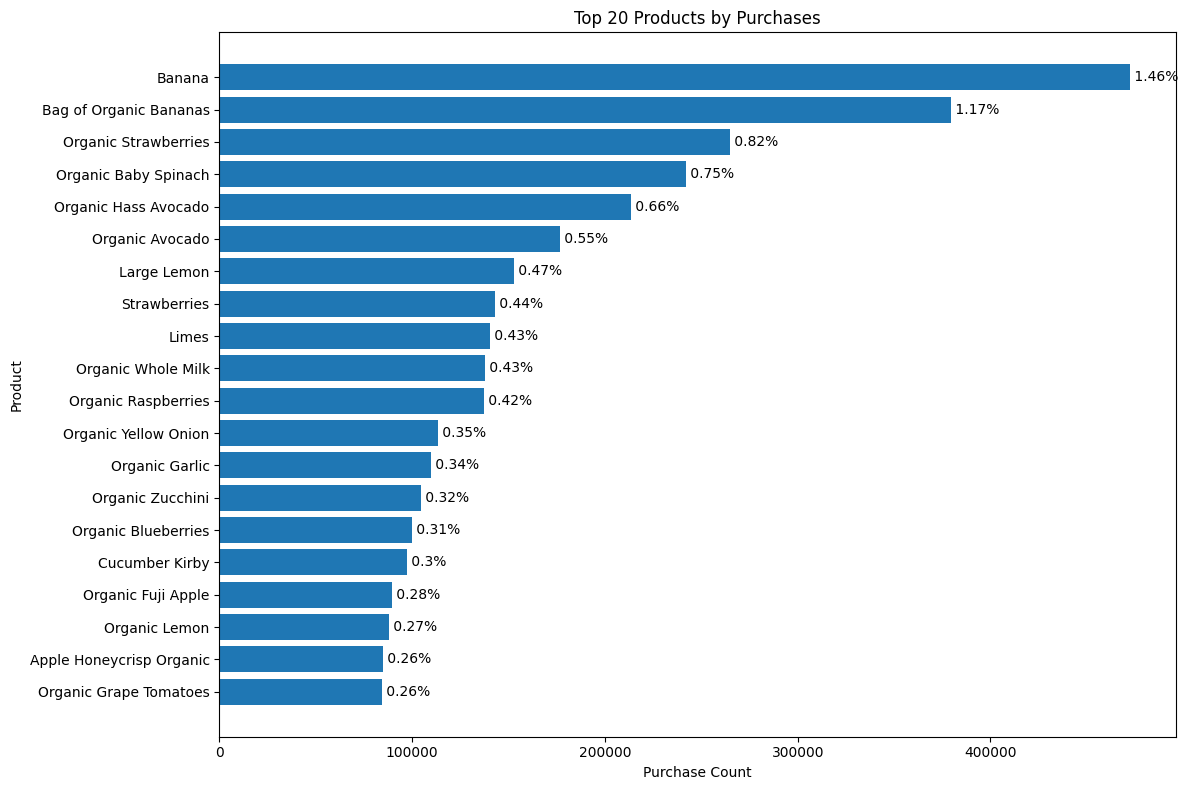

In [10]:
top_20_products = (
    user_products
    .groupby(["product_id", "product_name"])
    .size()
    .reset_index(name="purchase_count")
    .sort_values("purchase_count", ascending=False)
    .head(20)
)

total_purchases = len(user_products)

top_20_products["percent_of_total"] = (
    top_20_products["purchase_count"] / total_purchases * 100
).round(2)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_20_products["product_name"][::-1],
    top_20_products["purchase_count"][::-1]
)

for bar, pct in zip(bars, top_20_products["percent_of_total"][::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {pct}%",
        va="center"
    )

plt.title("Top 20 Products by Purchases")
plt.xlabel("Purchase Count")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [11]:
total_purchases = len(user_products)

top_20_aisles = (
    user_products
    .groupby("aisle")
    .size()
    .reset_index(name="purchase_count")
    .sort_values("purchase_count", ascending=False)
    .head(20)
)

top_20_aisles["percent_of_total"] = (
    top_20_aisles["purchase_count"] / total_purchases * 100
).round(2)

top_20_aisles

,aisle,purchase_count,percent_of_total
50,fresh fruits,3642188,11.23
53,fresh vegetables,3418021,10.54
98,packaged vegetables fruits,1765313,5.44
133,yogurt,1452343,4.48
93,packaged cheese,979763,3.02
83,milk,891015,2.75
131,water seltzer sparkling water,841533,2.59
25,chips pretzels,722470,2.23
119,soy lactosefree,638253,1.97
11,bread,584834,1.80


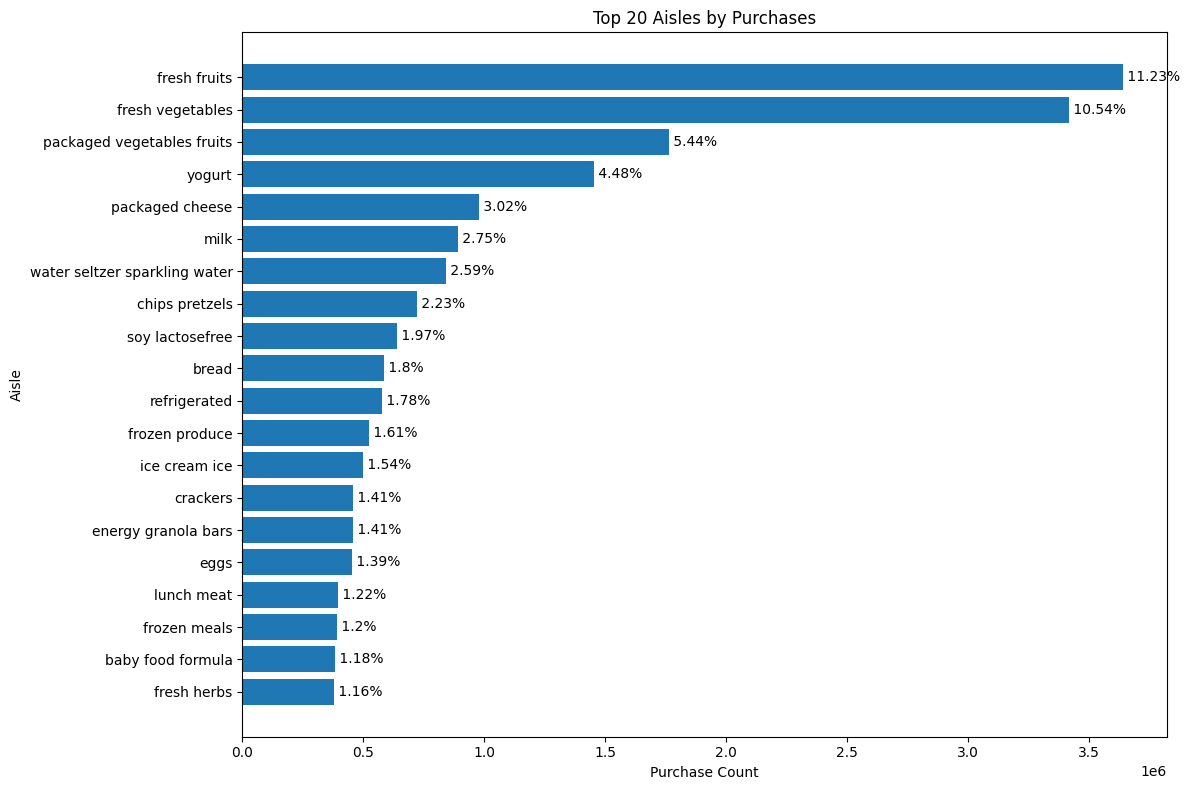

In [12]:
plt.figure(figsize=(12, 8))

bars = plt.barh(
    top_20_aisles["aisle"][::-1],
    top_20_aisles["purchase_count"][::-1]
)

for bar, pct in zip(bars, top_20_aisles["percent_of_total"][::-1]):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {pct}%",
        va="center"
    )

plt.title("Top 20 Aisles by Purchases")
plt.xlabel("Purchase Count")
plt.ylabel("Aisle")
plt.tight_layout()
plt.show()

In [13]:
department_purchases = (
    user_products
    .groupby("department")
    .size()
    .reset_index(name="purchase_count")
    .sort_values("purchase_count", ascending=False)
)

total_purchases = len(user_products)

department_purchases["percent_of_total"] = (
    department_purchases["purchase_count"] / total_purchases * 100
).round(2)

department_purchases

,department,purchase_count,percent_of_total
19,produce,9479291,29.23
7,dairy eggs,5414016,16.69
20,snacks,2887550,8.90
3,beverages,2690129,8.29
10,frozen,2236432,6.90
16,pantry,1875577,5.78
2,bakery,1176787,3.63
6,canned goods,1068058,3.29
8,deli,1051249,3.24
9,dry goods pasta,866627,2.67


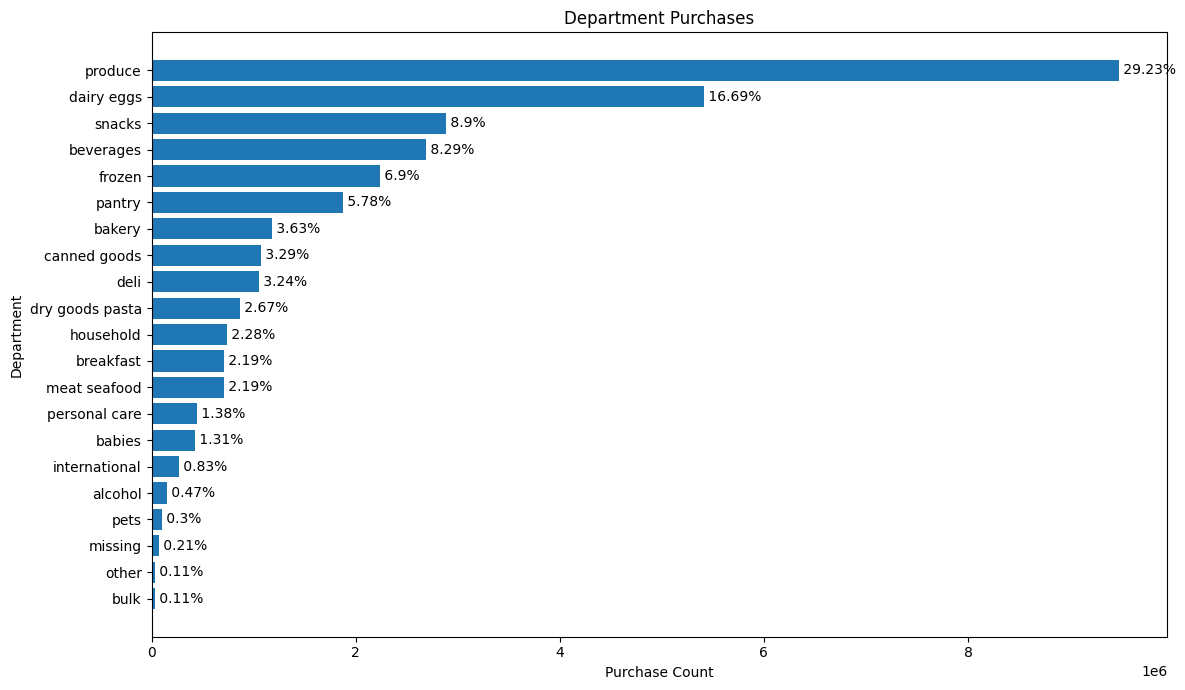

In [14]:
plt.figure(figsize=(12, 7))

bars = plt.barh(
    department_purchases["department"][::-1],
    department_purchases["purchase_count"][::-1]
)

for bar, pct in zip(
    bars,
    department_purchases["percent_of_total"][::-1]
):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {pct}%",
        va="center"
    )

plt.title("Department Purchases")
plt.xlabel("Purchase Count")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

# Foot Traffic into Aisles

1.   How many products per aisle is being purchased?
2.   Is there and how many products are not purchased?




In [15]:
# Different products per aisle being purchased
purchased_items_per_aisle = (
    user_products
    .groupby(["department", "aisle"])["product_id"]
    .nunique()
    .reset_index(name="purchased_items")
    .sort_values("purchased_items", ascending=False)
)

purchased_items_per_aisle

,department,aisle,purchased_items
85,missing,missing,1255
123,snacks,candy chocolate,1246
63,frozen,ice cream ice,1091
115,personal care,vitamins supplements,1038
42,dairy eggs,yogurt,1026
...,...,...,...
57,frozen,frozen juice,47
5,babies,baby accessories,44
121,produce,packaged produce,32
27,bulk,bulk grains rice dried goods,26


In [16]:
purchased_items_per_aisle.head(20)

,department,aisle,purchased_items
85,missing,missing,1255
123,snacks,candy chocolate,1246
63,frozen,ice cream ice,1091
115,personal care,vitamins supplements,1038
42,dairy eggs,yogurt,1026
124,snacks,chips pretzels,989
20,beverages,tea,894
38,dairy eggs,packaged cheese,890
58,frozen,frozen meals,880
125,snacks,cookies cakes,873


In [17]:
# Count of purchased and not purchased per aisle
aisle_purchase_analysis = (
    items_per_aisle
    .merge(
        purchased_items_per_aisle,
        on=["department", "aisle"],
        how="left"
    )
)

aisle_purchase_analysis["purchased_items"] = (
    aisle_purchase_analysis["purchased_items"]
    .fillna(0)
    .astype(int)
)

aisle_purchase_analysis["not_purchased"] = (
    aisle_purchase_analysis["number_of_items"]
    - aisle_purchase_analysis["purchased_items"]
)

aisle_purchase_analysis["purchase_coverage"] = (
    aisle_purchase_analysis["purchased_items"]
    / aisle_purchase_analysis["number_of_items"]
    * 100
)

aisle_purchase_analysis = aisle_purchase_analysis.sort_values(
    "purchase_coverage",
    ascending=True
)

aisle_purchase_analysis.head(10)

,department,aisle,number_of_items,purchased_items,not_purchased,purchase_coverage
99,breakfast,granola,185,184,1,99.459459
18,beverages,refrigerated,675,673,2,99.703704
54,household,air fresheners candles,355,354,1,99.718310
0,missing,missing,1258,1255,3,99.761526
34,pantry,spreads,493,492,1,99.797160
31,household,laundry,506,505,1,99.802372
9,snacks,cookies cakes,874,873,1,99.885584
7,dairy eggs,packaged cheese,891,890,1,99.887767
6,beverages,tea,894,894,0,100.000000
8,frozen,frozen meals,880,880,0,100.000000


In [18]:
# Items not purchased

purchased_product_ids = user_products["product_id"].unique()

not_purchased_products = products_full[
    ~products_full["product_id"].isin(purchased_product_ids)
]

not_purchased_products[
    ["product_id", "product_name", "department", "aisle"]
]

,product_id,product_name,department,aisle
3629,3630,Protein Granola Apple Crisp,breakfast,granola
3717,3718,Wasabi Cheddar Spreadable Cheese,dairy eggs,packaged cheese
7044,7045,Unpeeled Apricot Halves in Heavy Syrup,pantry,spreads
25382,25383,Chocolate Go Bites,snacks,cookies cakes
27498,27499,Non-Dairy Coconut Seven Layer Bar,missing,missing
36232,36233,Water With Electrolytes,missing,missing
37702,37703,Ultra Sun Blossom Liquid 90 loads Fabric Enhan...,household,laundry
43724,43725,Sweetart Jelly Beans,missing,missing
45970,45971,12 Inch Taper Candle White,household,air fresheners candles
46624,46625,Single Barrel Kentucky Straight Bourbon Whiskey,beverages,refrigerated


# Top Products and their reorder count - department, and aisle

1.   Top Products reorder count and percentage of reorder / total orders
2.   Bar Graph of Top Products Reordered
3.   Top Products Reordered Grouped by Departments and percentage of reorder / total orders
4.   Bar Graph of Top Products Reordered Grouped by Departments



In [19]:
# Top Products Reorder count and percentage
most_reordered = (
    user_products[user_products["reordered"] == 1]
    .groupby(["product_id", "product_name"])
    .size()
    .reset_index(name="reorder_count")
    .sort_values("reorder_count", ascending=False)
)

most_reordered["percent_of_total"] = (
    most_reordered["reorder_count"] /
    most_reordered["reorder_count"].sum() * 100
).round(2)

most_reordered.head(10)

,product_id,product_name,reorder_count,percent_of_total
22680,24852,Banana,398609,2.08
11997,13176,Bag of Organic Bananas,315913,1.65
19282,21137,Organic Strawberries,205845,1.08
19973,21903,Organic Baby Spinach,186884,0.98
43048,47209,Organic Hass Avocado,170131,0.89
43552,47766,Organic Avocado,134044,0.70
25420,27845,Organic Whole Milk,114510,0.60
43429,47626,Large Lemon,106255,0.56
25530,27966,Organic Raspberries,105409,0.55
15321,16797,Strawberries,99802,0.52


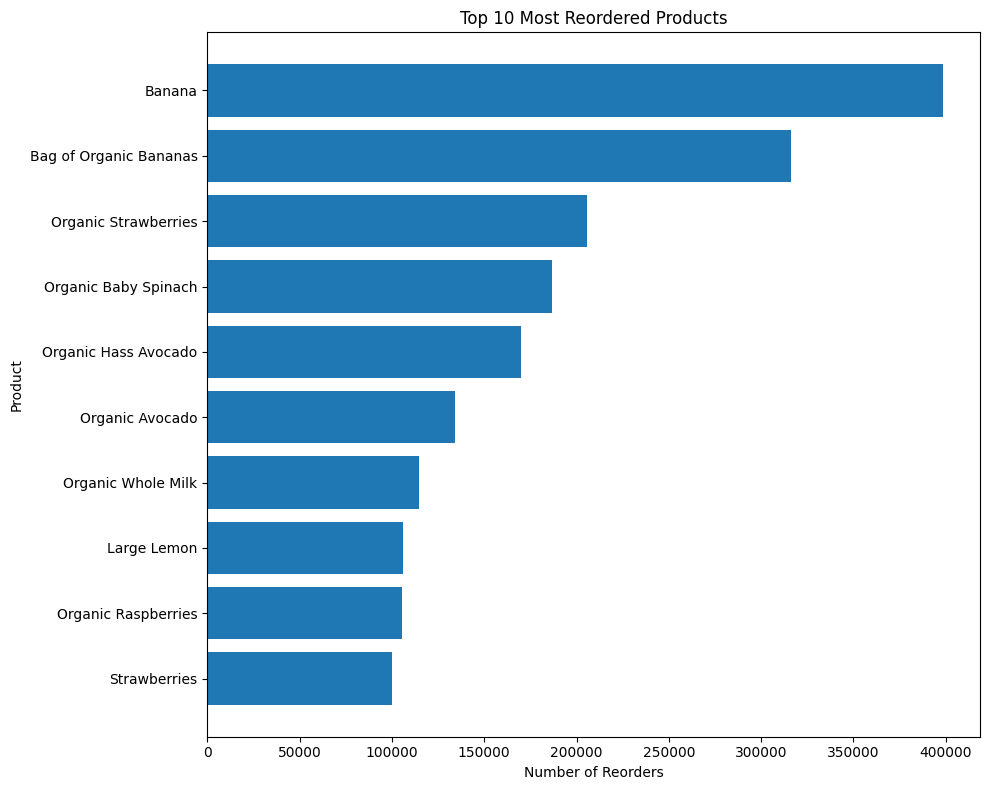

In [20]:
top_10_reordered = most_reordered.head(10).sort_values("reorder_count")

plt.figure(figsize=(10, 8))

plt.barh(
    top_10_reordered["product_name"],
    top_10_reordered["reorder_count"]
)

plt.title("Top 10 Most Reordered Products")
plt.xlabel("Number of Reorders")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [21]:
# Department
department_reorders = (
    user_products[user_products["reordered"] == 1]
    .groupby("department")
    .size()
    .reset_index(name="reorder_count")
    .sort_values("reorder_count", ascending=False)
)

department_reorders["percent_of_total"] = (
    department_reorders["reorder_count"] /
    department_reorders["reorder_count"].sum() * 100
).round(2)

department_reorders

,department,reorder_count,percent_of_total
19,produce,6160710,32.21
7,dairy eggs,3627221,18.96
3,beverages,1757892,9.19
20,snacks,1657973,8.67
10,frozen,1211890,6.34
2,bakery,739188,3.86
16,pantry,650301,3.40
8,deli,638864,3.34
6,canned goods,488535,2.55
13,meat seafood,402442,2.10


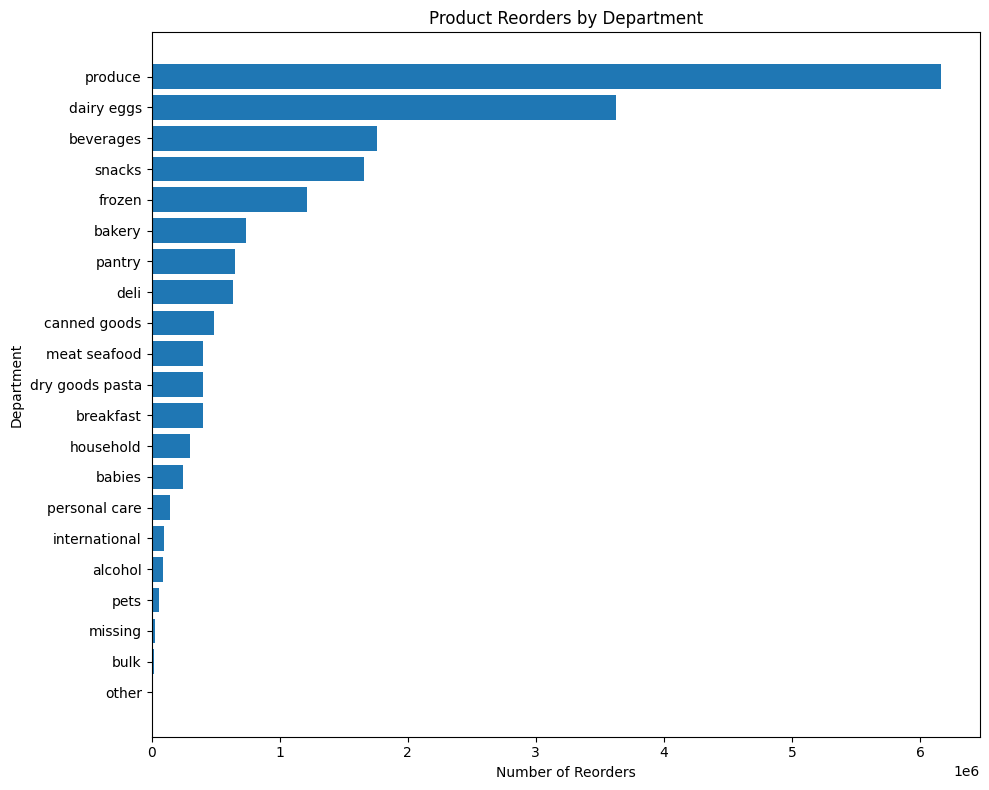

In [22]:
department_reorders_plot = department_reorders.sort_values(
    "reorder_count"
)

plt.figure(figsize=(10, 8))

plt.barh(
    department_reorders_plot["department"],
    department_reorders_plot["reorder_count"]
)

plt.title("Product Reorders by Department")
plt.xlabel("Number of Reorders")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

# Reorder Rate Analysis
1. Average reorder rate (Reorders / Total Purchases)
2. Product with highest reorder rate
3. 50th Percentile of purchase_count
4. Product with highest reorder rate (filtered by 50th percentile as minimum purchase count)

In [23]:
# Of all the purchased products, what is the % of reorders?
reorder_rate = (
    user_products["reordered"].sum()
    / len(user_products)
    * 100
)

print(f"Overall reorder rate: {reorder_rate:.2f}%")

Overall reorder rate: 58.97%


In [24]:
product_reorder_rate = (
    user_products
    .groupby(["product_id", "product_name"])
    .agg(
        total_purchases=("reordered", "count"),
        reorders=("reordered", "sum")
    )
    .reset_index()
)

product_reorder_rate["reorder_rate"] = (
    product_reorder_rate["reorders"]
    / product_reorder_rate["total_purchases"]
    * 100
)

product_reorder_rate = product_reorder_rate.sort_values(
    "reorder_rate",
    ascending=False
)

product_reorder_rate.head(10)

,product_id,product_name,total_purchases,reorders,reorder_rate
6430,6433,Raw Veggie Wrappers,68,64,94.117647
2074,2075,Serenity Ultimate Extrema Overnight Pads,87,81,93.103448
43545,43553,Orange Energy Shots,13,12,92.307692
27734,27740,Chocolate Love Bar,101,93,92.079208
14605,14609,Soy Powder Infant Formula,35,32,91.428571
13871,13875,Simply Sleep Nighttime Sleep Aid,45,41,91.111111
39984,39992,"Energy Shot, Grape Flavor",22,20,90.909091
31412,31418,Sparking Water,60,54,90.000000
5865,5868,Russian River Valley Reserve Pinot Noir,30,27,90.000000
35598,35604,Maca Buttercups,100,90,90.000000


In [25]:
# Sanity check: product_id matches product_name
print(user_products[user_products["product_id"] == 6433])

          user_id  order_id  product_id         product_name  reordered  \
301748      21777     31818        6433  Raw Veggie Wrappers          1   
1357701     21777    143173        6433  Raw Veggie Wrappers          1   
1365158     21777    143998        6433  Raw Veggie Wrappers          1   
1460949     68452    154038        6433  Raw Veggie Wrappers          0   
1461915    113578    154129        6433  Raw Veggie Wrappers          0   
...           ...       ...         ...                  ...        ...   
29219729    21777   3081644        6433  Raw Veggie Wrappers          1   
31022621    21777   3272270        6433  Raw Veggie Wrappers          1   
31190766    21777   3289861        6433  Raw Veggie Wrappers          1   
31336537    21777   3305152        6433  Raw Veggie Wrappers          1   
31400641    21777   3311960        6433  Raw Veggie Wrappers          1   

                   aisle department  
301748    prepared meals       deli  
1357701   prepared meal

In [26]:
# Determining minimum purchase count to limit analysis of reorder_rate
product_purchase_counts = (
    user_products
    .groupby(["product_id", "product_name"])
    .size()
    .reset_index(name="purchase_count")
)

product_purchase_counts.head()
product_purchase_counts["purchase_count"].describe()


,purchase_count
count,49677.000000
mean,652.907563
std,4792.114416
min,1.000000
25%,17.000000
50%,60.000000
75%,260.000000
max,472565.000000


In [27]:
product_purchase_counts["purchase_count"].quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
)

,purchase_count
0.10,7.0
0.25,17.0
0.50,60.0
0.75,260.0
0.90,1021.0
0.95,2286.0


## Reorder Rate Analysis for Products

In [28]:
minimum_purchases = 60

product_reorder_rate_filtered = product_reorder_rate[
    product_reorder_rate["total_purchases"] >= minimum_purchases
].sort_values(
    "reorder_rate",
    ascending=False
)

product_reorder_rate_filtered.head(10)

,product_id,product_name,total_purchases,reorders,reorder_rate
6430,6433,Raw Veggie Wrappers,68,64,94.117647
2074,2075,Serenity Ultimate Extrema Overnight Pads,87,81,93.103448
27734,27740,Chocolate Love Bar,101,93,92.079208
35598,35604,Maca Buttercups,100,90,90.000000
31412,31418,Sparking Water,60,54,90.000000
36536,36543,Bars Peanut Butter,67,60,89.552239
26088,26093,Soy Crisps Lightly Salted,66,59,89.393939
38243,38251,Benchbreak Chardonnay,111,99,89.189189
36794,36801,Organic Blueberry B Mega,96,85,88.541667
10232,10236,Fragrance Free Clay with Natural Odor Eliminat...,129,113,87.596899


In [29]:
# Count of top purchased products in designated department
top_30_reorder_products = (
    product_reorder_rate_filtered
    .head(30)
    .merge(
        user_products[["product_id", "department"]].drop_duplicates(),
        on="product_id",
        how="left"
    )
)

top_30_reorder_products[
    ["product_id", "product_name", "department",
     "total_purchases", "reorders", "reorder_rate"]
]

,product_id,product_name,department,total_purchases,reorders,reorder_rate
0,6433,Raw Veggie Wrappers,deli,68,64,94.117647
1,2075,Serenity Ultimate Extrema Overnight Pads,personal care,87,81,93.103448
2,27740,Chocolate Love Bar,snacks,101,93,92.079208
3,35604,Maca Buttercups,snacks,100,90,90.000000
4,31418,Sparking Water,beverages,60,54,90.000000
5,36543,Bars Peanut Butter,pantry,67,60,89.552239
6,26093,Soy Crisps Lightly Salted,snacks,66,59,89.393939
7,38251,Benchbreak Chardonnay,alcohol,111,99,89.189189
8,36801,Organic Blueberry B Mega,beverages,96,85,88.541667
9,10236,Fragrance Free Clay with Natural Odor Eliminat...,pets,129,113,87.596899


In [30]:
# Sanity check Reorder Rate of top product purchased
banana = product_reorder_rate[
    product_reorder_rate["product_name"].str.lower() == "banana"
]

banana

,product_id,product_name,total_purchases,reorders,reorder_rate
24848,24852,Banana,472565,398609,84.350089


## Reorder Rate Analysis for Departments

In [31]:
# Count of top purchased products in designated department
top_30_department_count = (
    top_30_reorder_products
    .groupby("department")
    .size()
    .reset_index(name="product_count")
    .sort_values("product_count", ascending=False)
)

top_30_department_count

,department,product_count
2,beverages,8
3,dairy eggs,8
8,snacks,5
0,alcohol,4
1,babies,1
4,deli,1
5,pantry,1
6,personal care,1
7,pets,1


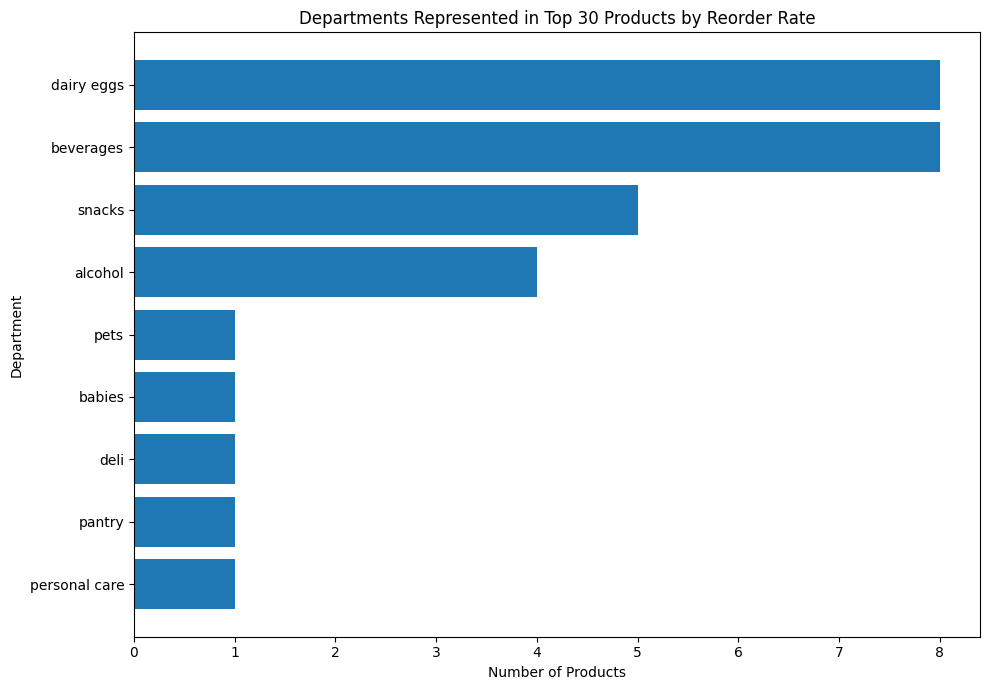

In [32]:
# Graph of Count of top purchased products in designated department
department_plot = top_30_department_count.sort_values("product_count")

plt.figure(figsize=(10, 7))

plt.barh(
    department_plot["department"],
    department_plot["product_count"]
)

plt.title("Departments Represented in Top 30 Products by Reorder Rate")
plt.xlabel("Number of Products")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

In [33]:
# Reorder Rate of top products purchased
product_analysis = (
    product_reorder_rate[
        product_reorder_rate["total_purchases"] >= 60
    ]
    .sort_values("total_purchases", ascending=False)
)

product_analysis[
    ["product_name",  "total_purchases", "reorders", "reorder_rate"]
].head(20)

,product_name,total_purchases,reorders,reorder_rate
24848,Banana,472565,398609,84.350089
13172,Bag of Organic Bananas,379450,315913,83.255501
21133,Organic Strawberries,264683,205845,77.770389
21899,Organic Baby Spinach,241921,186884,77.250011
47198,Organic Hass Avocado,213584,170131,79.655311
47755,Organic Avocado,176815,134044,75.810310
47615,Large Lemon,152657,106255,69.603752
16793,Strawberries,142951,99802,69.815531
26204,Limes,140627,95768,68.100720
27839,Organic Whole Milk,137905,114510,83.035423


In [34]:
# Reorder Rate of top products purchased including departments and aisles

top_30_products = (
    product_analysis
    .head(30)
    .merge(
        user_products[["product_id", "department", "aisle"]].drop_duplicates(),
        on="product_id",
        how="left"
    )
)

top_30_products[
    ["product_name", "department", "aisle" , "total_purchases", "reorders", "reorder_rate"]
]

,product_name,department,aisle,total_purchases,reorders,reorder_rate
0,Banana,produce,fresh fruits,472565,398609,84.350089
1,Bag of Organic Bananas,produce,fresh fruits,379450,315913,83.255501
2,Organic Strawberries,produce,fresh fruits,264683,205845,77.770389
3,Organic Baby Spinach,produce,packaged vegetables fruits,241921,186884,77.250011
4,Organic Hass Avocado,produce,fresh fruits,213584,170131,79.655311
5,Organic Avocado,produce,fresh fruits,176815,134044,75.810310
6,Large Lemon,produce,fresh fruits,152657,106255,69.603752
7,Strawberries,produce,fresh fruits,142951,99802,69.815531
8,Limes,produce,fresh fruits,140627,95768,68.100720
9,Organic Whole Milk,dairy eggs,milk,137905,114510,83.035423


In [35]:
# Count of top purchased products in designated department
top_30_departments = (
    top_30_products
    .groupby("department")
    .size()
    .reset_index(name="product_count")
    .sort_values("product_count", ascending=False)
)

top_30_departments

,department,product_count
2,produce,27
1,dairy eggs,2
0,beverages,1


In [36]:
# Count of top purchased products in designated aisle
top_30_aisle = (
    top_30_products
    .groupby("aisle")
    .size()
    .reset_index(name="product_count")
    .sort_values("product_count", ascending=False)
)

top_30_aisle

,aisle,product_count
1,fresh fruits,14
4,packaged vegetables fruits,7
2,fresh vegetables,6
0,cream,1
3,milk,1
5,water seltzer sparkling water,1
